In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../datos")
resultados_dir = Path("resultados")
resultados_dir.mkdir(exist_ok=True)

etiquetas = pd.read_csv(data_dir / "etiquetas_train.csv")
combos = pd.read_csv(data_dir / "combos_a_predecir.csv")

facturas_encabezado         = pd.read_parquet(data_dir / "oinv.parquet")
facturas_detalle            = pd.read_parquet(data_dir / "inv1.parquet")
notas_credito_encabezado    = pd.read_parquet(data_dir / "orin.parquet")
notas_credito_detalle       = pd.read_parquet(data_dir / "rin1.parquet")
catalogo_productos          = pd.read_parquet(data_dir / "oitm.parquet")
grupo_productos             = pd.read_parquet(data_dir / "oitb.parquet")
inventario_diario           = pd.read_parquet(data_dir / "inventario_regional.parquet")
ubicaciones                 = pd.read_parquet(data_dir / "obin.parquet")
bodegas                     = pd.read_parquet(data_dir / "owhs.parquet")

## B1. Riesgo de quedarse sin producto. ¿Qué combinaciones de SKU y bodega se van a quedar sin inventario pronto? Entrega la lista priorizada y explica cómo definiste "pronto".

### Métricas utilizadas

| Métrica | Definición y motivo |
| --- | --- |
| Stock disponible | Stock al 21 menos lo comprometido, con mínimo cero. Estima lo que queda libre. |
| Demanda diaria | Unidades facturadas divididas entre 7 o 21 días. Permite comparar ventas recientes con el período completo. |
| Días de cobertura | Stock disponible dividido entre demanda diaria. Indica para cuántos días alcanzaría. |

Se calcula por SKU y bodega, sumando ubicaciones. Se comparan ambos períodos porque los pedidos mayoristas pueden concentrarse en pocos días. N/A se trata como SKU no identificado. La demanda cero deja la cobertura sin calcular.

Se asume que el stock de las bodegas comerciales elegidas se puede usar dentro de esa bodega. Deben confirmarse restricciones de promociones o consignación antes de comprar o trasladar.


In [2]:
inventario_corte = inventario_diario.loc[
    inventario_diario["DataMartDate"].eq("2026-08-21")
].copy()
inventario_corte.loc[
    inventario_corte["SKU"].str.strip().str.upper().eq("N/A"), "SKU"
] = None


In [3]:
catalogo_priorizado = (
    catalogo_productos.assign(
        prioridad_segmento=(
            catalogo_productos["U_Segmento"].isna()
            | catalogo_productos["U_Segmento"].eq("SIN SEGMENTO")
        ).astype(int)
    )
    .sort_values(
        ["ItemCode", "prioridad_segmento", "U_Segmento"]
    )
    .drop_duplicates("ItemCode")
)

mapa_productos = catalogo_priorizado[["ItemCode", "InvntryUom"]].copy()
mapa_productos.loc[
    mapa_productos["InvntryUom"].str.strip().str.upper().eq("N/A"),
    "InvntryUom"
] = None

In [4]:
ventas_demanda = (
    facturas_detalle
    .merge(
        facturas_encabezado,
        on="DocEntry",
        validate="many_to_one"
    )
    .merge(
        mapa_productos,
        on="ItemCode",
        how="left",
        validate="many_to_one"
    )
    .rename(columns={"InvntryUom": "SKU"})
)

ventas_demanda = ventas_demanda.loc[
    ventas_demanda["Canceled"].eq("N")
    & ventas_demanda["DocDate"].ge("2026-08-01")
    & ventas_demanda["DocDate"].lt("2026-08-22")
].copy()

ventas_demanda.loc[
    ventas_demanda["SKU"].isna()
    | ventas_demanda["WhsCode"].isna()
    | ventas_demanda["Quantity"].lt(0)
]


,DocEntry,LineNum,ItemCode,WhsCode,U_Ubicacion,Quantity,LineTotal,StockValue,GrssProfit,DocDate,Canceled,DocSubType,DocCur,DocRate,SKU
1538,556190,2,SC-001,GT1SERV,NaN,1.0,312.50,0.00,312.50,2026-08-03,N,--,QTZ,1.0,None
1814,556341,0,SC-001,GT1SERV,NaN,1.0,3013.39,0.00,3013.39,2026-08-04,N,--,QTZ,1.0,None
1817,556342,0,SC-001,GT1SERV,NaN,1.0,580.36,0.00,580.36,2026-08-04,N,--,QTZ,1.0,None
2197,556486,0,GH82-33392A,GT1SERV,NaN,1.0,0.00,32.76,-32.76,2026-08-04,N,--,QTZ,1.0,None
2198,556486,1,GH82-33544A,GT1SERV,NaN,1.0,0.00,41.21,-41.21,2026-08-04,N,--,QTZ,1.0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18102,562353,0,SC-001,GT1SERV,NaN,1.0,580.36,0.00,580.36,2026-08-21,N,--,QTZ,1.0,None
18106,562356,0,SC-001,GT1SERV,NaN,1.0,892.86,0.00,892.86,2026-08-21,N,--,QTZ,1.0,None
18107,562357,0,SC-001,GT1SERV,NaN,1.0,312.50,0.00,312.50,2026-08-21,N,--,QTZ,1.0,None
18108,562358,0,SC-001,GT1SERV,NaN,1.0,580.36,0.00,580.36,2026-08-21,N,--,QTZ,1.0,None


In [5]:
ventas_con_producto = ventas_demanda.loc[
    ventas_demanda["SKU"].notna()
    & ventas_demanda["WhsCode"].notna()
    & ventas_demanda["Quantity"].gt(0)
].copy()

demanda_21_dias = (
    ventas_con_producto
    .groupby(["SKU", "WhsCode"], as_index=False)
    .agg(unidades_21_dias=("Quantity", "sum"))
)

demanda_7_dias = (
    ventas_con_producto.loc[
        ventas_con_producto["DocDate"].ge("2026-08-15")
    ]
    .groupby(["SKU", "WhsCode"], as_index=False)
    .agg(unidades_7_dias=("Quantity", "sum"))
)

demanda = demanda_21_dias.merge(
    demanda_7_dias,
    on=["SKU", "WhsCode"],
    how="left",
    validate="one_to_one"
)

demanda["unidades_7_dias"] = demanda["unidades_7_dias"].fillna(0)

demanda["demanda_diaria_21"] = demanda["unidades_21_dias"] / 21
demanda["demanda_diaria_7"] = demanda["unidades_7_dias"] / 7

demanda = demanda.rename(columns={"WhsCode": "CodigoAlmacen"})


In [6]:
stock_corte = (
    inventario_corte.loc[inventario_corte["SKU"].notna()]
    .groupby(["SKU", "CodigoAlmacen"], as_index=False)
    .agg(
        stock=("sum_Stock", "sum"),
        comprometido=("sum_Comprometido", "sum"),
        pedido=("sum_Pedido", "sum")
    )
)

stock_corte["stock_disponible"] = (
    stock_corte["stock"] - stock_corte["comprometido"]
).clip(lower=0)

In [7]:
riesgo_stock = stock_corte.merge(
    demanda,
    on=["SKU", "CodigoAlmacen"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

riesgo_stock["_merge"].value_counts()


_merge
left_only     5150
both          1307
right_only     184
Name: count, dtype: int64

In [8]:
riesgo_stock["dias_cobertura_21"] = float("nan")
riesgo_stock["dias_cobertura_7"] = float("nan")

calcular_21 = (
    riesgo_stock["stock_disponible"].notna()
    & riesgo_stock["demanda_diaria_21"].gt(0)
)

calcular_7 = (
    riesgo_stock["stock_disponible"].notna()
    & riesgo_stock["demanda_diaria_7"].gt(0)
)

riesgo_stock.loc[calcular_21, "dias_cobertura_21"] = (
    riesgo_stock.loc[calcular_21, "stock_disponible"]
    / riesgo_stock.loc[calcular_21, "demanda_diaria_21"]
)

riesgo_stock.loc[calcular_7, "dias_cobertura_7"] = (
    riesgo_stock.loc[calcular_7, "stock_disponible"]
    / riesgo_stock.loc[calcular_7, "demanda_diaria_7"]
)


In [9]:
ventas_demanda.loc[
    ventas_demanda["SKU"].isin([
        "SM-A075MZKECGU",
        "SM-A175FLBICGU"
    ])
    & ventas_demanda["WhsCode"].eq("GT1CEDI"),
    [
        "DocEntry", "LineNum", "DocDate",
        "ItemCode", "SKU", "Quantity", "LineTotal"
    ]
].sort_values(["SKU", "DocDate"])

,DocEntry,LineNum,DocDate,ItemCode,SKU,Quantity,LineTotal
10088,559057,0,2026-08-12,5654,SM-A075MZKECGU,2400.0,2524969.44
10089,559057,1,2026-08-12,5654,SM-A075MZKECGU,1370.0,1441336.72
10091,559059,0,2026-08-12,5654,SM-A075MZKECGU,3600.0,3787454.16
10092,559059,1,2026-08-12,5654,SM-A075MZKECGU,2400.0,2524969.44
4141,557098,0,2026-08-06,6065,SM-A175FLBICGU,2000.0,2165187.60
4142,557098,1,2026-08-06,6065,SM-A175FLBICGU,80.0,86607.50
4143,557098,2,2026-08-06,6065,SM-A175FLBICGU,700.0,757815.66
4144,557098,3,2026-08-06,6065,SM-A175FLBICGU,600.0,649556.28
4145,557098,4,2026-08-06,6065,SM-A175FLBICGU,620.0,671208.16
4146,557098,5,2026-08-06,6065,SM-A175FLBICGU,700.0,757815.66


In [10]:
candidatos = riesgo_stock.loc[
    riesgo_stock["dias_cobertura_21"].le(7)
    | riesgo_stock["dias_cobertura_7"].le(7)
].copy()

display(
    candidatos.sort_values(
        ["dias_cobertura_7", "dias_cobertura_21"],
        na_position="last"
    )
)

,SKU,CodigoAlmacen,stock,comprometido,pedido,stock_disponible,unidades_21_dias,unidades_7_dias,demanda_diaria_21,demanda_diaria_7,_merge,dias_cobertura_21,dias_cobertura_7
5280,SM-A075MZGGGTO,GT2CEDI,24.0,0.0,0.0,24.0,979.0,607.0,46.619048,86.714286,both,0.514811,0.276771
5286,SM-A075MZKGGTO,GT2CEDI,60.0,0.0,0.0,60.0,1344.0,901.0,64.000000,128.714286,both,0.937500,0.466149
2198,ET-SNL71MOEGWW,GT1CEDI,2.0,0.0,0.0,2.0,56.0,21.0,2.666667,3.000000,both,0.750000,0.666667
5276,SM-A075MLVGGTO,GT2CEDI,58.0,0.0,0.0,58.0,891.0,609.0,42.428571,87.000000,both,1.367003,0.666667
1235,EF-EF971CBEGWW,GT1CEDI,17.0,1.0,2.0,16.0,248.0,121.0,11.809524,17.285714,both,1.354839,0.925620
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3300,GH82-38236A,GT1SERV,1.0,0.0,0.0,1.0,3.0,0.0,0.142857,0.000000,both,7.000000,NaN
3305,GH82-38398A,GT1SERV,1.0,0.0,0.0,1.0,3.0,0.0,0.142857,0.000000,both,7.000000,NaN
3477,GH96-19256A,GT1SERV,1.0,0.0,0.0,1.0,3.0,0.0,0.142857,0.000000,both,7.000000,NaN
3495,GH96-20363A,GT1SERV,1.0,0.0,0.0,1.0,3.0,0.0,0.142857,0.000000,both,7.000000,NaN


### Criterio de riesgo

Pronto significa siete días. Se muestran los pares con cobertura de siete días o menos usando cualquiera de los dos promedios. Primero se ordenan por cobertura reciente y después se dejan los casos detectados solo con el promedio de 21 días.

Se usan cantidades facturadas como aproximación de demanda. No se descuentan créditos porque no todos representan devoluciones físicas. Los pedidos pendientes se muestran aparte porque no tienen fecha de llegada.

Se separan bodegas comerciales y de servicio. Tránsito, daño, reclamos, contingencia y maquila quedan fuera del ranking comercial. La estimación supone que las ventas continúan y no llegan nuevas existencias.


In [11]:
bodegas_comerciales = [
    "GT1CEDI", "GT2CEDI", "GT3CEDI",
    "GT1COMER", "GT2COMER", "GT3COMER", "GT1B2B"
]
bodegas_servicio = ["GT1SERV", "GT2SERV", "GT3SERV"]

riesgo_comercial = candidatos.loc[
    candidatos["CodigoAlmacen"].isin(bodegas_comerciales)
].copy()

riesgo_servicio = candidatos.loc[
    candidatos["CodigoAlmacen"].isin(bodegas_servicio)
].copy()

riesgo_comercial["revision_historica"] = (
    riesgo_comercial["dias_cobertura_7"].isna()
    | riesgo_comercial["dias_cobertura_7"].gt(7)
)

riesgo_comercial = riesgo_comercial.sort_values(
    ["revision_historica", "dias_cobertura_7", "dias_cobertura_21", "SKU", "CodigoAlmacen"],
    na_position="last"
)

columnas_riesgo = [
    "SKU", "CodigoAlmacen", "stock_disponible",
    "unidades_7_dias", "unidades_21_dias",
    "dias_cobertura_7", "dias_cobertura_21", "pedido"
]

print("Candidatos comerciales:", len(riesgo_comercial))
print("Con baja cobertura reciente:", (~riesgo_comercial["revision_historica"]).sum())
print("Solo revisión histórica:", riesgo_comercial["revision_historica"].sum())
display(riesgo_comercial[columnas_riesgo + ["revision_historica"]])

print("Candidatos de servicio:", len(riesgo_servicio))
display(riesgo_servicio[columnas_riesgo])


Candidatos comerciales: 62
Con baja cobertura reciente: 45
Solo revisión histórica: 17


,SKU,CodigoAlmacen,stock_disponible,unidades_7_dias,unidades_21_dias,dias_cobertura_7,dias_cobertura_21,pedido,revision_historica
5280,SM-A075MZGGGTO,GT2CEDI,24.0,607.0,979.0,0.276771,0.514811,0.0,False
5286,SM-A075MZKGGTO,GT2CEDI,60.0,901.0,1344.0,0.466149,0.937500,0.0,False
2198,ET-SNL71MOEGWW,GT1CEDI,2.0,21.0,56.0,0.666667,0.750000,0.0,False
5276,SM-A075MLVGGTO,GT2CEDI,58.0,609.0,891.0,0.666667,1.367003,0.0,False
1235,EF-EF971CBEGWW,GT1CEDI,16.0,121.0,248.0,0.925620,1.354839,2.0,False
...,...,...,...,...,...,...,...,...,...
4181,HW-B400F/ZP,GT1B2B,7.0,0.0,43.0,NaN,3.418605,0.0,True
5313,SM-A165MZAACGU,GT1CEDI,1100.0,0.0,5400.0,NaN,4.277778,0.0,True
2092,EP-T4511XBEGMX,GT2CEDI,8.0,0.0,32.0,NaN,5.250000,0.0,True
2293,FAF45,GT1CEDI,3.0,0.0,9.0,NaN,7.000000,0.0,True


Candidatos de servicio: 26


,SKU,CodigoAlmacen,stock_disponible,unidades_7_dias,unidades_21_dias,dias_cobertura_7,dias_cobertura_21,pedido
461,BN44-01303A,GT1SERV,2.0,0.0,7.0,NaN,6.000000,0.0
2755,GH81-26440A,GT1SERV,5.0,0.0,33.0,NaN,3.181818,0.0
2758,GH81-26447A,GT1SERV,3.0,0.0,35.0,NaN,1.800000,0.0
2768,GH81-26475A,GT1SERV,1.0,0.0,3.0,NaN,7.000000,0.0
2795,GH81-27197A,GT1SERV,1.0,0.0,8.0,NaN,2.625000,0.0
2799,GH81-27227A,GT1SERV,1.0,0.0,8.0,NaN,2.625000,0.0
2802,GH81-27282A,GT1SERV,2.0,0.0,8.0,NaN,5.250000,0.0
2825,GH81-27932A,GT1SERV,1.0,0.0,8.0,NaN,2.625000,0.0
3269,GH82-37578A,GT1SERV,2.0,0.0,7.0,NaN,6.000000,0.0
3286,GH82-37735A,GT1SERV,1.0,0.0,4.0,NaN,5.250000,0.0


### Ventas sin inventario al corte

Los pares con ventas pero sin observación de inventario al 21 se muestran aparte. Su stock se considera desconocido, no cero. Requieren confirmar existencias antes de estimar cobertura. La ausencia de ventas recientes tampoco permite calcular días de cobertura por ese período.


In [12]:
stock_desconocido = riesgo_stock.loc[
    riesgo_stock["_merge"].eq("right_only"),
    ["SKU", "CodigoAlmacen", "unidades_7_dias", "unidades_21_dias"]
].copy()

print("Pares con stock desconocido:", len(stock_desconocido))
display(stock_desconocido)

riesgo_comercial[columnas_riesgo + ["revision_historica"]].to_csv(
    resultados_dir / "b1_riesgo_comercial.csv", index=False
)
riesgo_servicio[columnas_riesgo].to_csv(
    resultados_dir / "b1_riesgo_servicio.csv", index=False
)
stock_desconocido.to_csv(resultados_dir / "b1_stock_desconocido.csv", index=False)


Pares con stock desconocido: 184


,SKU,CodigoAlmacen,unidades_7_dias,unidades_21_dias
44,15683,GT1CEDI,1.0,2.0
112,2378,GT1COMER,7.0,14.0
113,2379,GT1COMER,3.0,4.0
114,2380,GT1COMER,1.0,1.0
115,2381,GT1COMER,1.0,4.0
...,...,...,...,...
6462,UN75U8000FPXPA,GT1CEDI,27.0,29.0
6470,UN75U8000HPXPA,GT2CEDI,0.0,8.0
6494,UN85U8000HPXPA,GT2CEDI,0.0,1.0
6519,VG-SCFF75SGMZX,GT1COMER,0.0,1.0


### Historial de stock

Se revisa el stock físico diario de los primeros cinco candidatos comerciales. Las fechas sin observaciones se mantienen vacías para no representar un agotamiento falso, incluyendo el vacío de GT1CEDI del 15 al 17.

La tendencia sirve como contexto. Una caída puede deberse a ventas, traslados o ajustes, y un aumento puede reflejar entradas. Por eso no se interpreta cada cambio de stock como consumo ni se usa esta gráfica como una predicción por sí sola.


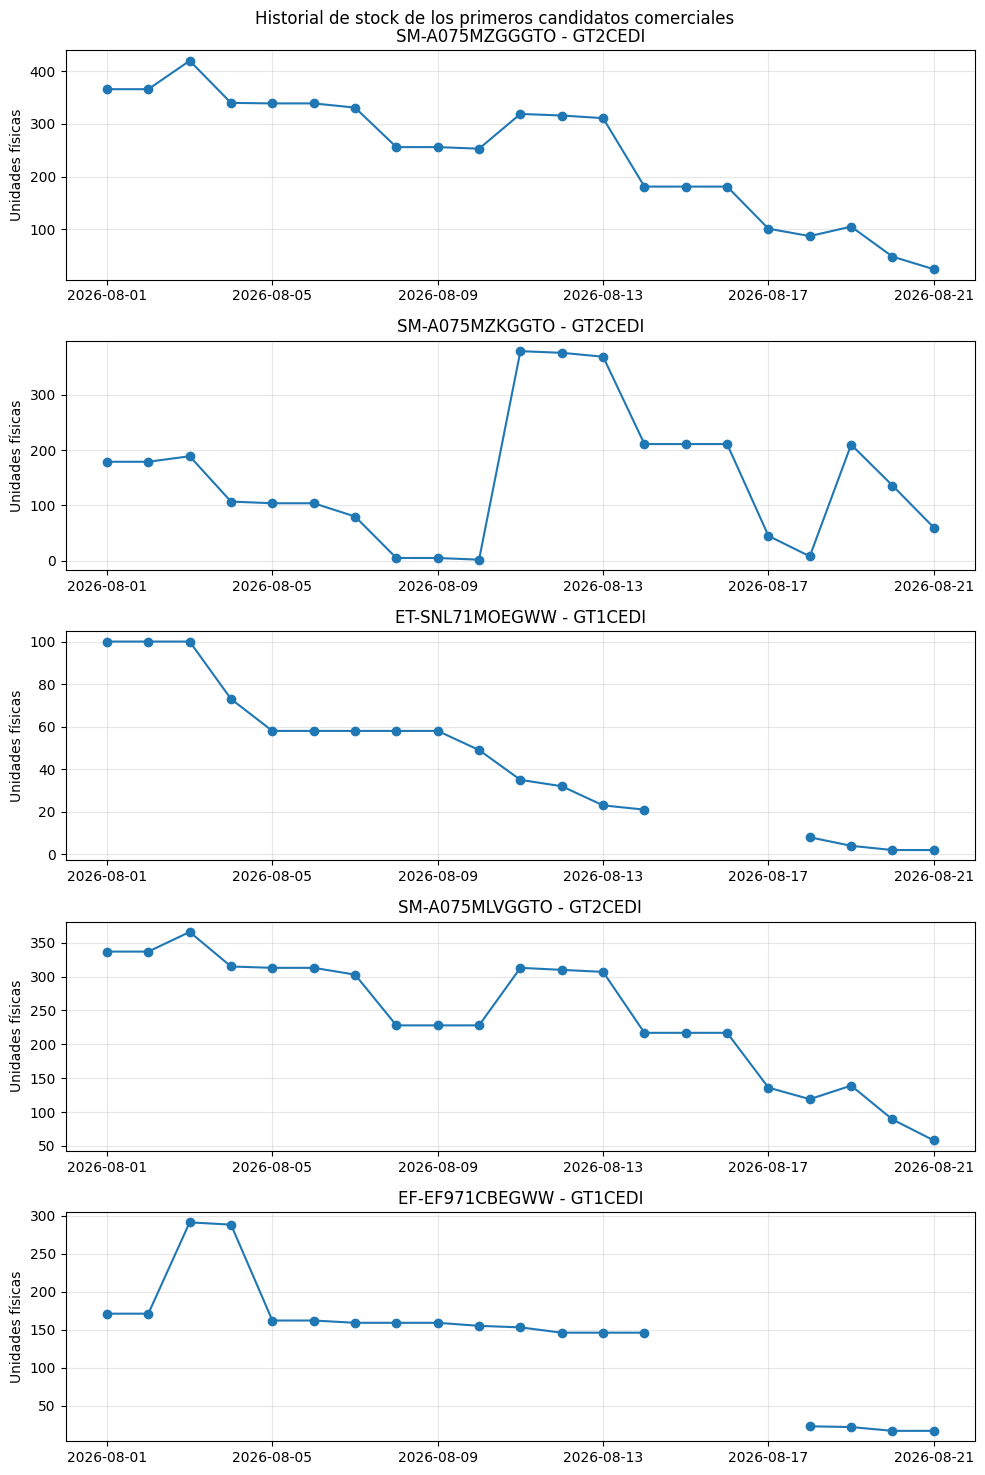

In [13]:
import matplotlib.pyplot as plt

primeros_candidatos = riesgo_comercial.head(5)
fechas = pd.date_range("2026-08-01", "2026-08-21")

figura, ejes = plt.subplots(
    len(primeros_candidatos), 1,
    figsize=(10, 3 * len(primeros_candidatos)),
    squeeze=False
)

for eje, (_, candidato) in zip(ejes[:, 0], primeros_candidatos.iterrows()):
    historial = inventario_diario.loc[
        inventario_diario["SKU"].eq(candidato["SKU"])
        & inventario_diario["CodigoAlmacen"].eq(candidato["CodigoAlmacen"])
    ]

    stock_diario = (
        historial.groupby("DataMartDate")["sum_Stock"]
        .sum()
        .reindex(fechas)
    )

    eje.plot(stock_diario.index, stock_diario.values, marker="o")
    eje.set_title(candidato["SKU"] + " - " + candidato["CodigoAlmacen"])
    eje.set_ylabel("Unidades físicas")
    eje.grid(alpha=0.3)

figura.suptitle("Historial de stock de los primeros candidatos comerciales")
figura.tight_layout()
figura.savefig(resultados_dir / "b1_historial_stock.png", dpi=150, bbox_inches="tight")
plt.show()


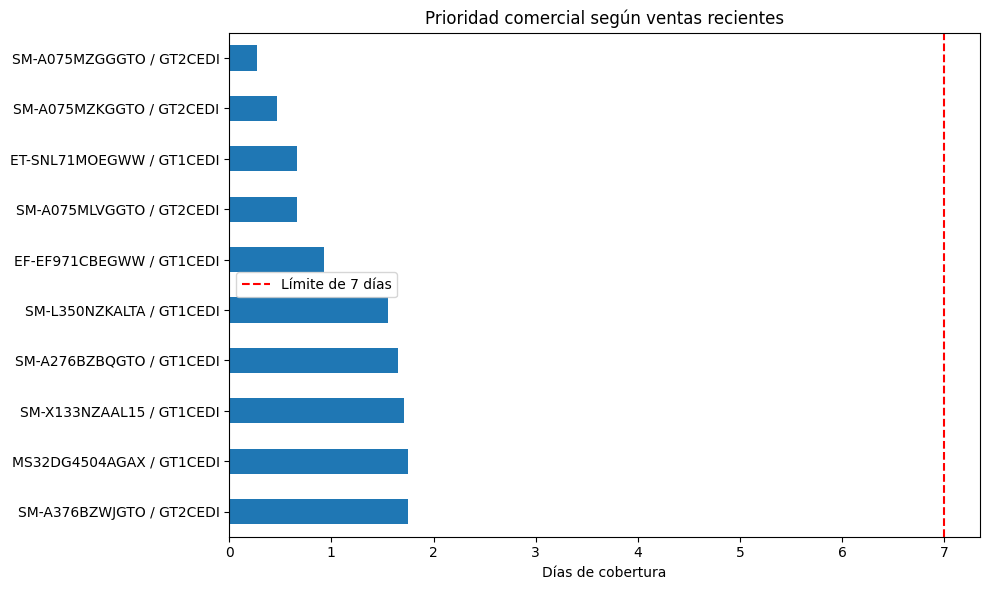

In [14]:
prioridad_reciente = riesgo_comercial.loc[
    ~riesgo_comercial["revision_historica"]
].head(10).copy()

prioridad_reciente["producto_bodega"] = (
    prioridad_reciente["SKU"] + " / " + prioridad_reciente["CodigoAlmacen"]
)

grafica = prioridad_reciente.plot.barh(
    x="producto_bodega", y="dias_cobertura_7",
    figsize=(10, 6), legend=False
)
grafica.axvline(7, color="red", linestyle="--", label="7 días")
grafica.invert_yaxis()
grafica.set_title("Prioridad comercial según ventas recientes")
grafica.set_xlabel("Días de cobertura")
grafica.set_ylabel("")
grafica.legend(["Límite de 7 días"])
plt.tight_layout()
plt.savefig(resultados_dir / "b1_cobertura.png", dpi=150, bbox_inches="tight")
plt.show()


### Resultado B1

Hay 45 pares comerciales de SKU y bodega con cobertura de siete días o menos usando las ventas del 15 al 21. Se ordenan de menor a mayor cobertura. Otros 17 aparecen solo con el promedio de 21 días y se muestran después. Los 26 casos de servicio quedan separados.

Por ejemplo, SM-A075MZGGGTO en GT2CEDI tiene 24 unidades y cobertura reciente de 0.28 días. Su stock observado baja de 366 a 24 unidades. Esto no prueba que todas las salidas sean ventas.

Hay 184 pares con ventas pero sin stock al corte. Quedan desconocidos. El vacío de GT1CEDI del 15 al 17 tampoco se interpreta como stock cero. Las listas completas están en resultados/.


In [15]:
resumen_b1 = pd.DataFrame({
    "indicador": [
        "Comerciales con cobertura reciente de 7 días o menos",
        "Comerciales solo para revisión histórica",
        "Candidatos de servicio",
        "Pares con stock desconocido, todas las bodegas"
    ],
    "cantidad": [
        int((~riesgo_comercial["revision_historica"]).sum()),
        int(riesgo_comercial["revision_historica"].sum()),
        len(riesgo_servicio),
        len(stock_desconocido)
    ]
})
display(resumen_b1)

historial_primeros = inventario_diario.merge(
    primeros_candidatos[["SKU", "CodigoAlmacen"]],
    on=["SKU", "CodigoAlmacen"],
    how="inner",
    validate="many_to_one"
)
historial_primeros = (
    historial_primeros
    .groupby(["SKU", "CodigoAlmacen", "DataMartDate"], as_index=False)
    .agg(stock_fisico=("sum_Stock", "sum"))
)
display(historial_primeros)

display(
    riesgo_comercial.loc[
        ~riesgo_comercial["revision_historica"], columnas_riesgo
    ].head(5).round(2)
)

resumen_b1.to_csv(resultados_dir / "b1_indicadores.csv", index=False)


,indicador,cantidad
0,Comerciales con cobertura reciente de 7 días o...,45
1,Comerciales solo para revisión histórica,17
2,Candidatos de servicio,26
3,"Pares con stock desconocido, todas las bodegas",184


,SKU,CodigoAlmacen,DataMartDate,stock_fisico
0,EF-EF971CBEGWW,GT1CEDI,2026-08-01,171
1,EF-EF971CBEGWW,GT1CEDI,2026-08-02,171
2,EF-EF971CBEGWW,GT1CEDI,2026-08-03,291
3,EF-EF971CBEGWW,GT1CEDI,2026-08-04,288
4,EF-EF971CBEGWW,GT1CEDI,2026-08-05,162
...,...,...,...,...
94,SM-A075MZKGGTO,GT2CEDI,2026-08-17,45
95,SM-A075MZKGGTO,GT2CEDI,2026-08-18,8
96,SM-A075MZKGGTO,GT2CEDI,2026-08-19,210
97,SM-A075MZKGGTO,GT2CEDI,2026-08-20,136


,SKU,CodigoAlmacen,stock_disponible,unidades_7_dias,unidades_21_dias,dias_cobertura_7,dias_cobertura_21,pedido
5280,SM-A075MZGGGTO,GT2CEDI,24.0,607.0,979.0,0.28,0.51,0.0
5286,SM-A075MZKGGTO,GT2CEDI,60.0,901.0,1344.0,0.47,0.94,0.0
2198,ET-SNL71MOEGWW,GT1CEDI,2.0,21.0,56.0,0.67,0.75,0.0
5276,SM-A075MLVGGTO,GT2CEDI,58.0,609.0,891.0,0.67,1.37,0.0
1235,EF-EF971CBEGWW,GT1CEDI,16.0,121.0,248.0,0.93,1.35,2.0


## B2. Productos vitales. ¿Qué SKUs son los más importantes para el negocio y cuánto inventario tienen? Usa la regla de clasificación que consideres correcta y explica por qué.

### Criterio de importancia

Se agrupan las ventas netas GTQ por SKU y se ordenan de mayor a menor. A reúne aproximadamente el primer 80% de las ventas positivas identificadas, B el siguiente 15% y C el resto. El producto que cruza el límite queda en la clase anterior.

Se consideran vitales los clase A porque concentran la mayor parte de las ventas. Esto mide importancia por ventas, no utilidad. Los pedidos mayoristas pueden tener mucho peso.

Los montos sin SKU o con N/A quedan separados. Los productos con venta neta cero o negativa también se muestran aparte.


In [16]:
# Se reutilizan las facturas elegibles preparadas en B1.
facturas_b2 = ventas_demanda.copy()
facturas_b2["VentaNetaGTQ"] = float("nan")

local = facturas_b2["DocCur"].eq("QTZ")
usd = facturas_b2["DocCur"].eq("USD")

facturas_b2.loc[local, "VentaNetaGTQ"] = facturas_b2.loc[local, "LineTotal"]
facturas_b2.loc[usd, "VentaNetaGTQ"] = (
    facturas_b2.loc[usd, "LineTotal"] * facturas_b2.loc[usd, "DocRate"]
)
assert facturas_b2["VentaNetaGTQ"].notna().all()

creditos_b2 = notas_credito_detalle.merge(
    notas_credito_encabezado, on="DocEntry", validate="many_to_one"
)
creditos_b2 = creditos_b2.loc[
    creditos_b2["Canceled"].eq("N")
    & creditos_b2["DocDate"].ge("2026-08-01")
    & creditos_b2["DocDate"].lt("2026-08-22")
].copy()

creditos_b2 = creditos_b2.merge(
    mapa_productos, on="ItemCode", how="left", validate="many_to_one"
).rename(columns={"InvntryUom": "SKU"})

# Mismo supuesto de la Parte A: créditos expresados en GTQ.
creditos_b2["VentaNetaGTQ"] = -creditos_b2["LineTotal"]

columnas_ventas = ["DocEntry", "LineNum", "SKU", "WhsCode", "VentaNetaGTQ"]
ventas_b2 = pd.concat(
    [facturas_b2[columnas_ventas], creditos_b2[columnas_ventas]],
    ignore_index=True
)

print("Venta neta total GTQ:", ventas_b2["VentaNetaGTQ"].sum())
print("Venta neta sin SKU GTQ:", ventas_b2.loc[
    ventas_b2["SKU"].isna(), "VentaNetaGTQ"
].sum())


Venta neta total GTQ: 129870049.0762
Venta neta sin SKU GTQ: -1087486.15


In [17]:
ventas_por_sku = (
    ventas_b2.loc[ventas_b2["SKU"].notna()]
    .groupby("SKU", as_index=False)
    .agg(venta_neta_gtq=("VentaNetaGTQ", "sum"))
)

clasificacion = ventas_por_sku.loc[
    ventas_por_sku["venta_neta_gtq"].gt(0)
].sort_values(["venta_neta_gtq", "SKU"], ascending=[False, True]).copy()

clasificacion["aporte_pct"] = (
    clasificacion["venta_neta_gtq"]
    / clasificacion["venta_neta_gtq"].sum() * 100
)
clasificacion["acumulado_pct"] = clasificacion["aporte_pct"].cumsum()
clasificacion["acumulado_anterior"] = clasificacion["acumulado_pct"].shift(fill_value=0)

clasificacion["clase"] = "C"
clasificacion.loc[clasificacion["acumulado_anterior"].lt(95), "clase"] = "B"
clasificacion.loc[clasificacion["acumulado_anterior"].lt(80), "clase"] = "A"

ventas_no_positivas = ventas_por_sku.loc[
    ventas_por_sku["venta_neta_gtq"].le(0)
].copy()

display(clasificacion.groupby("clase").agg(
    skus=("SKU", "size"),
    venta_neta_gtq=("venta_neta_gtq", "sum"),
    aporte_pct=("aporte_pct", "sum")
))
print("SKUs con venta neta cero o negativa:", len(ventas_no_positivas))


,skus,venta_neta_gtq,aporte_pct
clase,,,
A,40,1.049871e+08,80.096451
B,82,1.954865e+07,14.914002
C,687,6.540089e+06,4.989548


SKUs con venta neta cero o negativa: 304


### Inventario de los productos vitales

Se muestra el stock observado al 21 de agosto, tanto total como disponible en bodegas comerciales. Se usan los mismos criterios de B1.

El valor GTQ usa los costos registrados. Si faltan costos, el valor es parcial. Si falta inventario al corte, queda desconocido y no se reemplaza por cero ni por el último valor observado.


In [18]:
inventario_por_sku = (
    inventario_corte.loc[inventario_corte["SKU"].notna()]
    .groupby("SKU", as_index=False)
    .agg(
        stock_fisico_total=("sum_Stock", "sum"),
        valor_registrado_gtq=("sum_CostoTotal", lambda columna: columna.sum(min_count=1)),
        filas_sin_costo=("sum_CostoTotal", lambda columna: columna.isna().sum())
    )
)

stock_comercial = (
    stock_corte.loc[stock_corte["CodigoAlmacen"].isin(bodegas_comerciales)]
    .groupby("SKU", as_index=False)
    .agg(
        stock_fisico_comercial=("stock", "sum"),
        stock_disponible_comercial=("stock_disponible", "sum")
    )
)

productos_vitales = (
    clasificacion.loc[clasificacion["clase"].eq("A")]
    .merge(inventario_por_sku, on="SKU", how="left", validate="one_to_one")
    .merge(stock_comercial, on="SKU", how="left", validate="one_to_one")
)

alertas_vitales = riesgo_comercial.loc[
    ~riesgo_comercial["revision_historica"]
    & riesgo_comercial["SKU"].isin(productos_vitales["SKU"])
].copy()

display(productos_vitales.drop(columns="acumulado_anterior"))
display(alertas_vitales[columnas_riesgo])

productos_vitales.drop(columns="acumulado_anterior").to_csv(
    resultados_dir / "b2_productos_vitales.csv", index=False
)
clasificacion.drop(columns="acumulado_anterior").to_csv(
    resultados_dir / "b2_clasificacion_abc.csv", index=False
)
ventas_no_positivas.to_csv(resultados_dir / "b2_ventas_no_positivas.csv", index=False)


,SKU,venta_neta_gtq,aporte_pct,acumulado_pct,clase,stock_fisico_total,valor_registrado_gtq,filas_sin_costo,stock_fisico_comercial,stock_disponible_comercial
0,SM-A175FZKICGU,2.057492e+07,15.696960,15.696960,A,7864.0,8.096577e+06,0.0,7809.0,7809.0
1,SM-A075MZKECGU,1.027873e+07,7.841822,23.538782,A,31.0,2.235687e+04,0.0,2.0,2.0
2,SM-A175FLBICGU,9.747627e+06,7.436634,30.975416,A,70.0,7.209722e+04,0.0,55.0,55.0
3,SM-F976BZKLLTG,4.964410e+06,3.787435,34.762851,A,NaN,NaN,NaN,NaN,NaN
4,SM-F971BZKLLTG,4.825443e+06,3.681414,38.444265,A,NaN,NaN,NaN,NaN,NaN
5,SM-A165MZAACGU,4.566709e+06,3.484021,41.928287,A,1127.0,8.898683e+05,0.0,1121.0,1121.0
6,SM-A065MLGACGU,3.958516e+06,3.020021,44.948308,A,36.0,2.056498e+04,0.0,NaN,NaN
7,SM-S948BZKKL15,3.438064e+06,2.622959,47.571267,A,101.0,9.469109e+05,0.0,101.0,101.0
8,SM-A576BZANCGU,3.118175e+06,2.378910,49.950177,A,750.0,2.220484e+06,0.0,750.0,750.0
9,SM-A376BZACCGU,2.774506e+06,2.116719,52.066895,A,700.0,1.415869e+06,0.0,700.0,700.0


,SKU,CodigoAlmacen,stock_disponible,unidades_7_dias,unidades_21_dias,dias_cobertura_7,dias_cobertura_21,pedido
5280,SM-A075MZGGGTO,GT2CEDI,24.0,607.0,979.0,0.276771,0.514811,0.0
5286,SM-A075MZKGGTO,GT2CEDI,60.0,901.0,1344.0,0.466149,0.937500,0.0
5276,SM-A075MLVGGTO,GT2CEDI,58.0,609.0,891.0,0.666667,1.367003,0.0
5412,SM-A276BZBQGTO,GT1CEDI,77.0,326.0,326.0,1.653374,4.960123,0.0
5338,SM-A175FLBFGTO,GT1CEDI,37.0,140.0,316.0,1.850000,2.458861,0.0
5588,SM-A576BZVFGTO,GT2CEDI,7.0,16.0,54.0,3.062500,2.722222,0.0
6437,UN65U8000HPXPA,GT3COMER,58.0,102.0,102.0,3.980392,11.941176,0.0
5558,SM-A576BDBFGTO,GT2CEDI,13.0,18.0,47.0,5.055556,5.808511,0.0


In [19]:
resumen_b2 = pd.DataFrame({
    "indicador": [
        "SKUs clase A",
        "Aporte de clase A a la venta neta positiva identificada (%)",
        "Venta neta GTQ de clase A",
        "SKUs clase A con alerta comercial reciente",
        "Pares SKU y bodega clase A con alerta comercial reciente"
    ],
    "valor": [
        len(productos_vitales),
        productos_vitales["aporte_pct"].sum(),
        productos_vitales["venta_neta_gtq"].sum(),
        alertas_vitales["SKU"].nunique(),
        len(alertas_vitales)
    ]
})
display(resumen_b2)

resumen_b2.to_csv(resultados_dir / "b2_indicadores.csv", index=False)


,indicador,valor
0,SKUs clase A,4.000000e+01
1,Aporte de clase A a la venta neta positiva ide...,8.009645e+01
2,Venta neta GTQ de clase A,1.049871e+08
3,SKUs clase A con alerta comercial reciente,8.000000e+00
4,Pares SKU y bodega clase A con alerta comercia...,8.000000e+00


### Resultado B2

Los 40 SKUs clase A concentran el 80.10% de la venta neta positiva identificada. Son los productos vitales según el criterio de aporte a ventas. Ocho tienen además una alerta comercial reciente en B1.

Hay 8 productos clase A sin observación de inventario al corte. Su stock queda desconocido. El stock total y el comercial disponible se muestran por separado en la tabla.

N/A se separó como SKU no identificado y no se cuenta como producto. Los pedidos mayoristas influyen en esta clasificación, que no mide rentabilidad. La lista completa está en resultados/b2_productos_vitales.csv.


## B3. Dinero detenido. ¿Qué mercadería ocupa bodega sin venderse y cuánto dinero representa? Ordena por el valor en riesgo.

### Criterio de inventario sin ventas

Se considera dinero detenido el stock al 21 de agosto sin unidades facturadas en su bodega del 1 al 21. Se ordena por costo GTQ porque permite identificar dónde hay más dinero registrado.

También se indica si el SKU tuvo ventas en otra bodega. Una venta y su devolución no se tratan como ausencia de ventas.

Solo se observaron 21 días. No se afirma que el stock sea obsoleto o una pérdida, ya que podría ser nuevo, de reserva o para servicio.


In [20]:
# N/A es una referencia no identificada y se separa del análisis por SKU.
sku_identificado = (
    inventario_corte["SKU"].notna()
    & inventario_corte["SKU"].str.strip().ne("")
    & inventario_corte["SKU"].str.strip().str.upper().ne("N/A")
)

inventario_b3 = inventario_corte.loc[sku_identificado].copy()
inventario_sin_sku = inventario_corte.loc[~sku_identificado].copy()

stock_por_bodega = (
    inventario_b3
    .groupby(["SKU", "CodigoAlmacen"], as_index=False)
    .agg(
        stock_fisico=("sum_Stock", "sum"),
        comprometido=("sum_Comprometido", "sum"),
        valor_registrado_gtq=("sum_CostoTotal", lambda columna: columna.sum(min_count=1)),
        filas_sin_costo=("sum_CostoTotal", lambda columna: columna.isna().sum())
    )
)

ventas_b3 = ventas_con_producto.loc[
    ventas_con_producto["SKU"].str.strip().ne("")
    & ventas_con_producto["SKU"].str.strip().str.upper().ne("N/A")
].copy()

unidades_por_bodega = (
    ventas_b3.groupby(["SKU", "WhsCode"], as_index=False)
    .agg(unidades_vendidas=("Quantity", "sum"))
    .rename(columns={"WhsCode": "CodigoAlmacen"})
)

inventario_con_ventas = stock_por_bodega.merge(
    unidades_por_bodega,
    on=["SKU", "CodigoAlmacen"],
    how="left",
    validate="one_to_one"
)

# Sin coincidencia significa sin ventas registradas, no stock desconocido.
inventario_con_ventas["unidades_vendidas"] = (
    inventario_con_ventas["unidades_vendidas"].fillna(0)
)

inventario_sin_ventas = inventario_con_ventas.loc[
    inventario_con_ventas["unidades_vendidas"].eq(0)
    & inventario_con_ventas["stock_fisico"].gt(0)
].copy()


In [21]:
inventario_sin_ventas["sin_ventas_en_empresa"] = (
    ~inventario_sin_ventas["SKU"].isin(ventas_b3["SKU"])
)
inventario_sin_ventas["bodega_comercial"] = (
    inventario_sin_ventas["CodigoAlmacen"].isin(bodegas_comerciales)
)
inventario_sin_ventas["valor_incompleto"] = (
    inventario_sin_ventas["filas_sin_costo"].gt(0)
)

inventario_sin_ventas = inventario_sin_ventas.merge(
    bodegas[["WhsCode", "WhsName"]],
    left_on="CodigoAlmacen",
    right_on="WhsCode",
    how="left",
    validate="many_to_one"
).drop(columns="WhsCode")

inventario_sin_ventas = inventario_sin_ventas.sort_values(
    ["valor_registrado_gtq", "SKU", "CodigoAlmacen"],
    ascending=[False, True, True],
    na_position="last"
)

display(inventario_sin_ventas.head(20))
inventario_sin_ventas.to_csv(resultados_dir / "b3_inventario_sin_ventas.csv", index=False)

resumen_b3_bodegas = (
    inventario_sin_ventas
    .groupby(["CodigoAlmacen", "WhsName", "bodega_comercial"], as_index=False)
    .agg(
        pares_sku_bodega=("SKU", "size"),
        stock_fisico=("stock_fisico", "sum"),
        valor_registrado_gtq=("valor_registrado_gtq", lambda columna: columna.sum(min_count=1)),
        filas_sin_costo=("filas_sin_costo", "sum")
    )
    .sort_values("valor_registrado_gtq", ascending=False)
)
display(resumen_b3_bodegas)
resumen_b3_bodegas.to_csv(resultados_dir / "b3_resumen_bodegas.csv", index=False)


,SKU,CodigoAlmacen,stock_fisico,comprometido,valor_registrado_gtq,filas_sin_costo,unidades_vendidas,sin_ventas_en_empresa,bodega_comercial,valor_incompleto,WhsName
4310,SM-A276BZKACGU,GT1CEDI,8492,0,1.482765e+07,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
4786,SM-S948BZKMLTG,GT1CEDI,520,0,4.876706e+06,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
4101,RT35DG5224S9AP,GT3CEDI,241,0,7.034893e+05,0,0.0,False,True,False,RDUS (CD)
4651,SM-S741BZVJGTOR,GT3CEDI,300,0,6.905107e+05,0,0.0,True,True,False,RDUS (CD)
3840,QN55Q6FAAPXPA,GT1TRAN,253,0,6.774555e+05,0,0.0,False,False,False,TRANSITO
4027,RF80H30JETED,GT1CEDI,57,0,6.570989e+05,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
3569,MNA110MS1ACXXA,GT1CEDI,1,0,6.464626e+05,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
326,AM260CXVAFC/AZ,GT1CEDI,8,0,6.242108e+05,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
3441,LH46VMBUBGBXGO,GT1CEDI,65,0,6.056690e+05,0,0.0,True,True,False,CENTRO DE DISTRIBUCIÓN (CD)
4649,SM-S741BZKJGTOR,GT3CEDI,240,0,5.527682e+05,0,0.0,True,True,False,RDUS (CD)


,CodigoAlmacen,WhsName,bodega_comercial,pares_sku_bodega,stock_fisico,valor_registrado_gtq,filas_sin_costo
1,GT1CEDI,CENTRO DE DISTRIBUCIÓN (CD),True,1077,56269,4.077326e+07,0
2,GT1COMER,PUNTOS DE VENTA OFFLINE,True,881,11185,1.106422e+07,14
10,GT3CEDI,RDUS (CD),True,38,1596,3.536775e+06,0
6,GT1SERV,SERVICE CENTER,False,1702,5740,3.480345e+06,1
0,GT1B2B,PROYECTOS B2B,True,176,7068,2.374406e+06,0
4,GT1DAÑO,PRODUCTO DAÑADO,False,408,1125,2.266339e+06,0
3,GT1CONTI,ALMACEN DE CONTINGENCIA,False,234,1327,1.778758e+06,0
8,GT2CEDI,TIER 3 (CD),True,57,4259,1.552946e+06,0
7,GT1TRAN,TRANSITO,False,190,2454,1.478473e+06,0
12,GT3SERV,SERVICE CENTER OTROS,False,207,365,1.416689e+06,0


### Límites de la valoración

El valor registrado no representa una pérdida confirmada ni el dinero que se recuperaría al vender. Si faltan costos, el valor es parcial y no se completa con cero. Las filas sin SKU se muestran aparte porque no se puede confirmar si sus productos tuvieron ventas.

Los totales solo cubren existencias observadas al 21 de agosto. No se trasladan automáticamente valores de fechas anteriores. El stock comprometido se conserva en la lista para distinguir existencias que podrían tener demanda pendiente.


In [22]:
comercial_sin_ventas = inventario_sin_ventas.loc[
    inventario_sin_ventas["bodega_comercial"]
]
sin_ventas_empresa = inventario_sin_ventas.loc[
    inventario_sin_ventas["sin_ventas_en_empresa"]
]

resumen_b3 = pd.DataFrame({
    "indicador": [
        "Pares SKU y bodega sin ventas registradas",
        "Valor GTQ registrado sin ventas en su bodega",
        "Valor GTQ en bodegas comerciales sin ventas en su bodega",
        "Valor GTQ de stock de SKUs sin ventas en toda la empresa",
        "Filas sin costo dentro del inventario sin ventas",
        "Filas de inventario al corte sin SKU identificado",
        "Valor GTQ registrado sin SKU identificado"
    ],
    "valor": [
        len(inventario_sin_ventas),
        inventario_sin_ventas["valor_registrado_gtq"].sum(min_count=1),
        comercial_sin_ventas["valor_registrado_gtq"].sum(min_count=1),
        sin_ventas_empresa["valor_registrado_gtq"].sum(min_count=1),
        inventario_sin_ventas["filas_sin_costo"].sum(),
        len(inventario_sin_sku),
        inventario_sin_sku["sum_CostoTotal"].sum(min_count=1)
    ]
})
display(resumen_b3)
inventario_sin_sku.to_csv(resultados_dir / "b3_inventario_sin_sku.csv", index=False)

resumen_b3.to_csv(resultados_dir / "b3_indicadores.csv", index=False)


,indicador,valor
0,Pares SKU y bodega sin ventas registradas,5.150000e+03
1,Valor GTQ registrado sin ventas en su bodega,7.263734e+07
2,Valor GTQ en bodegas comerciales sin ventas en...,6.051614e+07
3,Valor GTQ de stock de SKUs sin ventas en toda ...,5.779540e+07
4,Filas sin costo dentro del inventario sin ventas,1.500000e+01
5,Filas de inventario al corte sin SKU identificado,5.000000e+00
6,Valor GTQ registrado sin SKU identificado,1.710418e+06


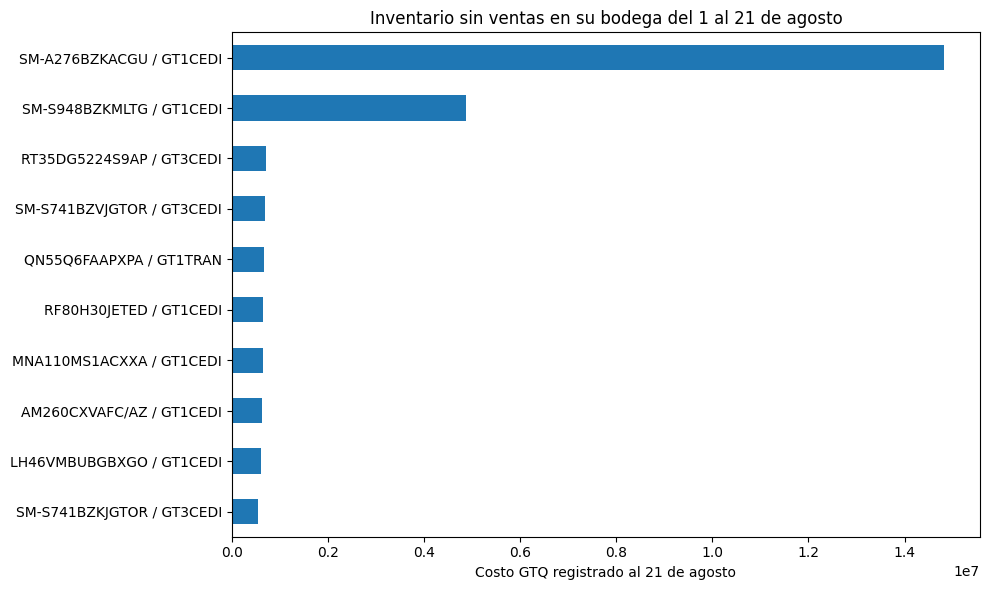

In [23]:
mayor_valor = inventario_sin_ventas.loc[
    inventario_sin_ventas["valor_registrado_gtq"].notna()
].head(10).copy()

mayor_valor["producto_bodega"] = (
    mayor_valor["SKU"] + " / " + mayor_valor["CodigoAlmacen"]
)

grafica_b3 = mayor_valor.plot.barh(
    x="producto_bodega", y="valor_registrado_gtq",
    figsize=(10, 6), legend=False
)
grafica_b3.invert_yaxis()
grafica_b3.set_title("Inventario sin ventas en su bodega del 1 al 21 de agosto")
grafica_b3.set_xlabel("Costo GTQ registrado al 21 de agosto")
grafica_b3.set_ylabel("")
plt.tight_layout()
plt.savefig(resultados_dir / "b3_inventario_sin_ventas.png", dpi=150, bbox_inches="tight")
plt.show()


### Resultado B3

Hay 5,150 pares de SKU y bodega con stock al 21 y sin ventas registradas en esa bodega del 1 al 21. El valor registrado es Q72,637,341.25, de los cuales Q60,516,141.21 están en bodegas comerciales.

De ese mismo total, Q57,795,403.09 corresponden a SKUs sin ventas en ninguna bodega. Es un subconjunto y no se suma de nuevo. SM-A276BZKACGU y SM-S948BZKMLTG en GT1CEDI encabezan la lista por valor.

La valoración es parcial porque 15 observaciones de la lista no tienen costo. Otras 5 observaciones sin SKU, con Q1,710,418.21 de costo registrado, quedan aparte. No tener ventas en estos 21 días no demuestra obsolescencia ni pérdida. La lista ordenada está en resultados/b3_inventario_sin_ventas.csv.


## B4. Rentabilidad. ¿Qué combinaciones de grupo de artículo y canal ganan más, y en cuáles se pierde dinero? Indica qué resultados no son confiables y por qué.

### Métricas de rentabilidad

Utilidad bruta = venta neta GTQ menos costo neto GTQ. Muestra cuánto aporta cada grupo y canal antes de gastos operativos.

Margen bruto = utilidad bruta dividida entre venta neta, por 100. Permite comparar grupos de distinto tamaño. No se calcula sobre ventas netas cero o negativas.

El canal viene de la ubicación. Los datos sin grupo o canal se mantienen separados.

En USD se convierte LineTotal y GrssProfit con DocRate, pero no StockValue. Esta interpretación coincide con las relaciones observadas en los datos. Los créditos se consideran GTQ y se restan tanto sus ingresos como sus costos.


In [24]:
facturas_rentabilidad = facturas_b2.copy()
facturas_rentabilidad["TipoDocumento"] = "FACTURA"
facturas_rentabilidad["CostoNetoGTQ"] = facturas_rentabilidad["StockValue"]
facturas_rentabilidad["UtilidadRegistradaGTQ"] = facturas_rentabilidad["GrssProfit"]
facturas_rentabilidad.loc[
    facturas_rentabilidad["DocCur"].eq("USD"), "UtilidadRegistradaGTQ"
] = (
    facturas_rentabilidad.loc[facturas_rentabilidad["DocCur"].eq("USD"), "GrssProfit"]
    * facturas_rentabilidad.loc[facturas_rentabilidad["DocCur"].eq("USD"), "DocRate"]
)

creditos_rentabilidad = creditos_b2.copy()
creditos_rentabilidad["TipoDocumento"] = "NOTA_CREDITO"
creditos_rentabilidad["CostoNetoGTQ"] = -creditos_rentabilidad["StockValue"]
creditos_rentabilidad["UtilidadRegistradaGTQ"] = -creditos_rentabilidad["GrssProfit"]

columnas_rentabilidad = [
    "TipoDocumento", "DocEntry", "LineNum", "ItemCode",
    "WhsCode", "U_Ubicacion", "VentaNetaGTQ",
    "CostoNetoGTQ", "UtilidadRegistradaGTQ"
]
rentabilidad = pd.concat(
    [
        facturas_rentabilidad[columnas_rentabilidad],
        creditos_rentabilidad[columnas_rentabilidad]
    ],
    ignore_index=True
)

rentabilidad["UtilidadBrutaGTQ"] = (
    rentabilidad["VentaNetaGTQ"] - rentabilidad["CostoNetoGTQ"]
)
rentabilidad["diferencia_utilidad_gtq"] = (
    rentabilidad["UtilidadBrutaGTQ"] - rentabilidad["UtilidadRegistradaGTQ"]
)
rentabilidad["utilidad_no_coincide"] = (
    rentabilidad["diferencia_utilidad_gtq"].abs().gt(0.10)
)

display(facturas_rentabilidad.loc[
    facturas_rentabilidad["DocCur"].eq("USD"),
    ["DocEntry", "LineNum", "VentaNetaGTQ", "CostoNetoGTQ", "UtilidadRegistradaGTQ"]
].head(10))

print("Mayor diferencia USD GTQ:", (
    facturas_rentabilidad.loc[facturas_rentabilidad["DocCur"].eq("USD"), "VentaNetaGTQ"]
    - facturas_rentabilidad.loc[facturas_rentabilidad["DocCur"].eq("USD"), "CostoNetoGTQ"]
    - facturas_rentabilidad.loc[facturas_rentabilidad["DocCur"].eq("USD"), "UtilidadRegistradaGTQ"]
).abs().max())


,DocEntry,LineNum,VentaNetaGTQ,CostoNetoGTQ,UtilidadRegistradaGTQ
49,555259,0,2766.1026,2355.11,410.9590
50,555259,1,0.9192,78.51,-77.5958
51,555259,2,66.9484,72.47,-5.5152
52,555259,3,40.2150,26.98,13.1752
61,555263,0,1695.6176,2297.93,-602.3824
73,555270,0,133.8968,90.92,42.9726
495,555560,0,9463.3938,7457.03,2006.3838
814,555768,0,5356.2550,4845.80,510.4624
815,555768,1,26.8100,0.00,26.8100
1175,555990,0,1516.9864,1186.79,330.1460


Mayor diferencia USD GTQ: 0.07380000000000564


In [25]:
rentabilidad = (
    rentabilidad
    .merge(
        catalogo_priorizado[["ItemCode", "ItmsGrpCod"]],
        on="ItemCode", how="left", validate="many_to_one"
    )
    .merge(
        grupo_productos, on="ItmsGrpCod", how="left", validate="many_to_one"
    )
    .merge(
        ubicaciones[["AbsEntry", "Canal"]],
        left_on="U_Ubicacion", right_on="AbsEntry",
        how="left", validate="many_to_one"
    )
)

rentabilidad["grupo_desconocido"] = (
    rentabilidad["GrupoArticulo"].isna()
    | rentabilidad["GrupoArticulo"].str.strip().eq("")
)
rentabilidad["canal_desconocido"] = (
    rentabilidad["Canal"].isna()
    | rentabilidad["Canal"].str.strip().eq("")
)

rentabilidad.loc[rentabilidad["grupo_desconocido"], "GrupoArticulo"] = "SIN GRUPO"
rentabilidad.loc[rentabilidad["canal_desconocido"], "Canal"] = "SIN CANAL"

rentabilidad["revisar_linea"] = (
    rentabilidad["grupo_desconocido"]
    | rentabilidad["canal_desconocido"]
    | rentabilidad["utilidad_no_coincide"]
)

rentabilidad["costo_cero_con_venta"] = (
    rentabilidad["CostoNetoGTQ"].eq(0) & rentabilidad["VentaNetaGTQ"].gt(0)
)

rentabilidad_grupo_canal = (
    rentabilidad
    .groupby(["GrupoArticulo", "Canal"], as_index=False)
    .agg(
        venta_neta_gtq=("VentaNetaGTQ", "sum"),
        costo_neto_gtq=("CostoNetoGTQ", "sum"),
        utilidad_bruta_gtq=("UtilidadBrutaGTQ", "sum"),
        lineas=("DocEntry", "size"),
        lineas_a_revisar=("revisar_linea", "sum"),
        diferencias_utilidad=("utilidad_no_coincide", "sum"),
        lineas_costo_cero_con_venta=("costo_cero_con_venta", "sum")
    )
)

rentabilidad_grupo_canal["margen_bruto_pct"] = float("nan")
ventas_positivas = rentabilidad_grupo_canal["venta_neta_gtq"].gt(0)

rentabilidad_grupo_canal.loc[ventas_positivas, "margen_bruto_pct"] = (
    rentabilidad_grupo_canal.loc[ventas_positivas, "utilidad_bruta_gtq"]
    / rentabilidad_grupo_canal.loc[ventas_positivas, "venta_neta_gtq"] * 100
)

rentabilidad_grupo_canal = rentabilidad_grupo_canal.sort_values(
    "utilidad_bruta_gtq", ascending=False
)

display(rentabilidad_grupo_canal)
print("Total de líneas:", len(rentabilidad))
print("Venta neta GTQ:", rentabilidad["VentaNetaGTQ"].sum())
print("Líneas con utilidad inconsistente:", rentabilidad["utilidad_no_coincide"].sum())

rentabilidad_grupo_canal.to_csv(resultados_dir / "b4_rentabilidad_grupo_canal.csv", index=False)
rentabilidad.loc[rentabilidad["revisar_linea"]].to_csv(
    resultados_dir / "b4_lineas_a_revisar.csv", index=False
)


,GrupoArticulo,Canal,venta_neta_gtq,costo_neto_gtq,utilidad_bruta_gtq,lineas,lineas_a_revisar,diferencias_utilidad,lineas_costo_cero_con_venta,margen_bruto_pct
22,TELEFONIA Y ACC,DISTY,1.033425e+08,97813967.36,5.528569e+06,1715,0,0,0,5.349752
23,TELEFONIA Y ACC,RETAIL,1.424297e+07,11230621.73,3.012345e+06,8893,0,0,0,21.149700
1,AUDIO Y VIDEO,DISTY,6.350443e+06,5706012.86,6.444303e+05,339,0,0,0,10.147800
16,REPUESTOS,SIN CANAL,9.321150e+05,405830.55,5.262844e+05,1512,1512,0,74,56.461321
11,LINEA BLANCA,RETAIL,2.452411e+06,1952882.94,4.995284e+05,598,0,0,0,20.368866
18,SERVICIOS,RETAIL,2.743829e+05,0.00,2.743829e+05,709,0,0,699,100.000000
2,AUDIO Y VIDEO,RETAIL,1.176530e+06,1008955.41,1.675741e+05,396,0,0,0,14.243085
10,LINEA BLANCA,DISTY,2.205693e+06,2040751.30,1.649419e+05,175,0,0,0,7.478006
0,AUDIO Y VIDEO,B2B,8.452927e+05,706384.12,1.389086e+05,100,0,0,0,16.433191
21,TELEFONIA Y ACC,B2B,3.884669e+05,333046.00,5.542095e+04,53,0,0,0,14.266580


Total de líneas: 18739
Venta neta GTQ: 129870049.0762
Líneas con utilidad inconsistente: 58


### Confiabilidad

Sin grupo o canal no se puede asignar el resultado a una categoría conocida. Se revisan diferencias mayores a Q0.10 entre utilidad calculada y registrada.

Un costo cero puede ser válido o estar incompleto. No demuestra que vender o prestar el servicio no tenga costos. Estos resultados no incluyen gastos operativos.


In [26]:
grupos_identificados = rentabilidad_grupo_canal.loc[
    rentabilidad_grupo_canal["GrupoArticulo"].ne("SIN GRUPO")
    & rentabilidad_grupo_canal["Canal"].ne("SIN CANAL")
].copy()

grupos_con_perdida = grupos_identificados.loc[
    grupos_identificados["utilidad_bruta_gtq"].lt(0)
].sort_values("utilidad_bruta_gtq")

print("Mayor utilidad bruta entre grupos y canales identificados:")
display(grupos_identificados.head(5))
print("Grupos y canales con pérdida bruta:")
display(grupos_con_perdida)

resumen_b4 = pd.DataFrame({
    "indicador": [
        "Venta neta total GTQ",
        "Costo neto total GTQ",
        "Utilidad bruta calculada total GTQ",
        "Combinaciones identificadas con pérdida bruta",
        "Líneas con utilidad inconsistente",
        "Líneas sin canal identificado",
        "Líneas sin grupo identificado"
    ],
    "valor": [
        rentabilidad["VentaNetaGTQ"].sum(),
        rentabilidad["CostoNetoGTQ"].sum(),
        rentabilidad["UtilidadBrutaGTQ"].sum(),
        len(grupos_con_perdida),
        rentabilidad["utilidad_no_coincide"].sum(),
        rentabilidad["canal_desconocido"].sum(),
        rentabilidad["grupo_desconocido"].sum()
    ]
})
display(resumen_b4)
resumen_b4.to_csv(resultados_dir / "b4_indicadores.csv", index=False)


Mayor utilidad bruta entre grupos y canales identificados:


,GrupoArticulo,Canal,venta_neta_gtq,costo_neto_gtq,utilidad_bruta_gtq,lineas,lineas_a_revisar,diferencias_utilidad,lineas_costo_cero_con_venta,margen_bruto_pct
22,TELEFONIA Y ACC,DISTY,1.033425e+08,97813967.36,5.528569e+06,1715,0,0,0,5.349752
23,TELEFONIA Y ACC,RETAIL,1.424297e+07,11230621.73,3.012345e+06,8893,0,0,0,21.149700
1,AUDIO Y VIDEO,DISTY,6.350443e+06,5706012.86,6.444303e+05,339,0,0,0,10.147800
11,LINEA BLANCA,RETAIL,2.452411e+06,1952882.94,4.995284e+05,598,0,0,0,20.368866
18,SERVICIOS,RETAIL,2.743829e+05,0.00,2.743829e+05,709,0,0,699,100.000000


Grupos y canales con pérdida bruta:


,GrupoArticulo,Canal,venta_neta_gtq,costo_neto_gtq,utilidad_bruta_gtq,lineas,lineas_a_revisar,diferencias_utilidad,lineas_costo_cero_con_venta,margen_bruto_pct
7,INSUMOS,RETAIL,35.67,9219.32,-9183.65,3910,0,0,0,-25746.14522


,indicador,valor
0,Venta neta total GTQ,1.298700e+08
1,Costo neto total GTQ,1.209815e+08
2,Utilidad bruta calculada total GTQ,8.888499e+06
3,Combinaciones identificadas con pérdida bruta,1.000000e+00
4,Líneas con utilidad inconsistente,5.800000e+01
5,Líneas sin canal identificado,1.638000e+03
6,Líneas sin grupo identificado,5.800000e+01


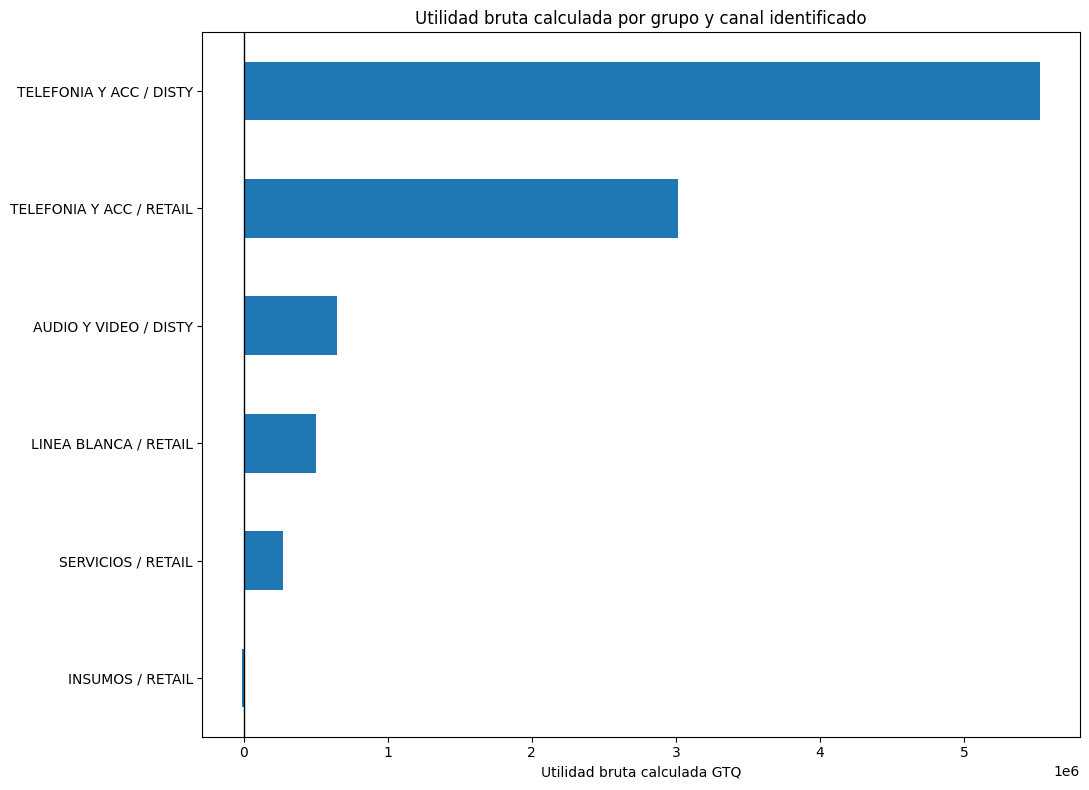

In [27]:
grafica_rentabilidad = pd.concat([
    grupos_identificados.head(5), grupos_con_perdida
]).drop_duplicates(["GrupoArticulo", "Canal"])
grafica_rentabilidad["grupo_canal"] = (
    grafica_rentabilidad["GrupoArticulo"] + " / " + grafica_rentabilidad["Canal"]
)

grafica_b4 = grafica_rentabilidad.plot.barh(
    x="grupo_canal", y="utilidad_bruta_gtq",
    figsize=(11, 8), legend=False
)
grafica_b4.axvline(0, color="black", linewidth=1)
grafica_b4.invert_yaxis()
grafica_b4.set_title("Utilidad bruta calculada por grupo y canal identificado")
grafica_b4.set_xlabel("Utilidad bruta calculada GTQ")
grafica_b4.set_ylabel("")
plt.tight_layout()
plt.savefig(resultados_dir / "b4_rentabilidad.png", dpi=150, bbox_inches="tight")
plt.show()


### Resultado B4

TELEFONIA Y ACC en DISTY aporta la mayor utilidad bruta identificada, Q5,528,568.94 con margen de 5.35%. En RETAIL aporta Q3,012,344.62 con margen de 21.15%. DISTY gana más en monto, pero RETAIL tiene mejor margen porcentual.

INSUMOS en RETAIL pierde Q9,183.65. Sus ventas netas son Q35.67, por lo que es más útil revisar el monto de pérdida que su porcentaje extremo.

Hay 1,638 líneas sin canal y 58 sin grupo. Estas 58 también tienen diferencias de utilidad. Sus importes se conservan, pero no permiten identificar correctamente el origen del resultado.

SERVICIOS presenta margen de 100% en RETAIL y B2B porque el costo registrado es cero. No se puede concluir que el servicio no tenga costos. El detalle está en resultados/b4_rentabilidad_grupo_canal.csv y las ventas concilian con la Parte A.


## B5. Recomendación. Con base en B1 a B4, da tres acciones concretas para la próxima semana, cada una con el monto en GTQ que está en juego.

### Acciones para la próxima semana


Se proponen tres acciones simples: revisar reposición de productos A con baja cobertura, pausar compras de productos sin ventas y revisar la pérdida de INSUMOS en RETAIL. Los montos representan cosas distintas y no se suman como ahorro.

Para la reposición se calcula lo necesario para cubrir siete días con el ritmo reciente. Se usa el costo promedio registrado al corte como referencia, no una cotización. Los pedidos pendientes no se descuentan sin confirmar su fecha de llegada.


In [28]:
import math

reposicion = alertas_vitales.merge(
    stock_por_bodega[
        ["SKU", "CodigoAlmacen", "stock_fisico", "valor_registrado_gtq", "filas_sin_costo"]
    ],
    on=["SKU", "CodigoAlmacen"],
    how="left",
    validate="one_to_one"
)

reposicion["unidades_a_reponer"] = (
    reposicion["unidades_7_dias"] - reposicion["stock_disponible"]
).clip(lower=0).apply(math.ceil)

reposicion["costo_unitario_gtq"] = float("nan")
costo_disponible = (
    reposicion["stock_fisico"].gt(0)
    & reposicion["valor_registrado_gtq"].gt(0)
    & reposicion["filas_sin_costo"].eq(0)
)
reposicion.loc[costo_disponible, "costo_unitario_gtq"] = (
    reposicion.loc[costo_disponible, "valor_registrado_gtq"]
    / reposicion.loc[costo_disponible, "stock_fisico"]
)
reposicion["costo_estimado_gtq"] = (
    reposicion["unidades_a_reponer"] * reposicion["costo_unitario_gtq"]
)

display(reposicion[[
    "SKU", "CodigoAlmacen", "stock_disponible", "unidades_7_dias",
    "unidades_a_reponer", "pedido", "costo_unitario_gtq", "costo_estimado_gtq"
]])
print("Pares sin costo estimado:", reposicion["costo_estimado_gtq"].isna().sum())
reposicion.to_csv(resultados_dir / "b5_reposicion.csv", index=False)


,SKU,CodigoAlmacen,stock_disponible,unidades_7_dias,unidades_a_reponer,pedido,costo_unitario_gtq,costo_estimado_gtq
0,SM-A075MZGGGTO,GT2CEDI,24.0,607.0,583,0.0,715.417500,417088.402500
1,SM-A075MZKGGTO,GT2CEDI,60.0,901.0,841,0.0,713.202667,599803.442947
2,SM-A075MLVGGTO,GT2CEDI,58.0,609.0,551,0.0,705.413966,388683.095266
3,SM-A276BZBQGTO,GT1CEDI,77.0,326.0,249,0.0,2503.772727,623439.409023
4,SM-A175FLBFGTO,GT1CEDI,37.0,140.0,103,0.0,1061.424054,109326.677562
5,SM-A576BZVFGTO,GT2CEDI,7.0,16.0,9,0.0,3275.804286,29482.238574
6,UN65U8000HPXPA,GT3COMER,58.0,102.0,44,0.0,3372.099828,148372.392432
7,SM-A576BDBFGTO,GT2CEDI,13.0,18.0,5,0.0,3296.436923,16482.184615


Pares sin costo estimado: 0


In [29]:
compras_a_revisar = inventario_sin_ventas.loc[
    inventario_sin_ventas["bodega_comercial"]
    & inventario_sin_ventas["sin_ventas_en_empresa"]
    & ~inventario_sin_ventas["valor_incompleto"]
    & inventario_sin_ventas["valor_registrado_gtq"].gt(0)
].head(5).copy()

display(compras_a_revisar[[
    "SKU", "CodigoAlmacen", "stock_fisico", "comprometido", "valor_registrado_gtq"
]])

perdida_insumos = rentabilidad_grupo_canal.loc[
    rentabilidad_grupo_canal["GrupoArticulo"].eq("INSUMOS")
    & rentabilidad_grupo_canal["Canal"].eq("RETAIL"),
    "utilidad_bruta_gtq"
].iloc[0]

acciones_b5 = pd.DataFrame({
    "accion": [
        "Confirmar stock y entregas de productos A en riesgo y evaluar reposición",
        "Pausar compras nuevas de los cinco pares sin ventas seleccionados",
        "Revisar precios, costos y entregas sin cobro de INSUMOS en RETAIL"
    ],
    "monto_gtq": [
        reposicion["costo_estimado_gtq"].sum(min_count=1),
        compras_a_revisar["valor_registrado_gtq"].sum(min_count=1),
        abs(perdida_insumos)
    ],
    "que_representa": [
        "Costo estimado para completar siete días, antes de confirmar entradas",
        "Costo registrado del stock a revisar, no ahorro garantizado",
        "Pérdida bruta observada del 1 al 21, no pérdida futura estimada"
    ]
})
display(acciones_b5)
acciones_b5.to_csv(resultados_dir / "b5_acciones.csv", index=False)
compras_a_revisar.to_csv(resultados_dir / "b5_compras_a_revisar.csv", index=False)


,SKU,CodigoAlmacen,stock_fisico,comprometido,valor_registrado_gtq
4310,SM-A276BZKACGU,GT1CEDI,8492,0,1.482765e+07
4786,SM-S948BZKMLTG,GT1CEDI,520,0,4.876706e+06
4651,SM-S741BZVJGTOR,GT3CEDI,300,0,6.905107e+05
4027,RF80H30JETED,GT1CEDI,57,0,6.570989e+05
3569,MNA110MS1ACXXA,GT1CEDI,1,0,6.464626e+05


,accion,monto_gtq,que_representa
0,Confirmar stock y entregas de productos A en r...,2.332678e+06,"Costo estimado para completar siete días, ante..."
1,Pausar compras nuevas de los cinco pares sin v...,2.169843e+07,"Costo registrado del stock a revisar, no ahorr..."
2,"Revisar precios, costos y entregas sin cobro d...",9.183650e+03,"Pérdida bruta observada del 1 al 21, no pérdid..."


### Resultado B5

1. **Revisar reposición de productos vitales con poco stock.** Durante la próxima semana, confirmar existencias y pedidos de los 8 pares clase A con alerta reciente. Para completar siete días al ritmo actual se estiman 2,385 unidades por Q2,332,677.84, usando el costo registrado. Antes de comprar se deben confirmar fechas de entrega, posibles traslados y precios actuales.

2. **Pausar compras nuevas de los cinco pares sin ventas seleccionados.** Representan Q21,698,427.94 de stock comercial registrado. Esta semana se debe revisar si existen pedidos pendientes o demanda futura antes de seguir comprando. Un traslado solo se evalúa si se confirma demanda en otra bodega. El monto es inventario a revisar, no ahorro garantizado.

3. **Revisar INSUMOS en RETAIL.** La pérdida bruta observada es Q9,183.65. Esta semana se deben revisar precios, costos y artículos entregados sin cobro antes de cambiar precios. Es una pérdida del período analizado y no una predicción para la próxima semana.

Las tres cifras no se suman. La primera es un costo estimado de reposición, la segunda es valor de inventario y la tercera es una pérdida ya observada. Los cálculos están en las tablas anteriores y los archivos resultados/b5_*.csv.
